# Лабораторная работа 1. Иерархический кластерный анализ

Сегментация потребителей леденцов по мотивам потребления. Датасет "Леденцы": 11 переменных (опрос 338 респондентов).


## Цель

Выделить интерпретируемые сегменты потребителей по мотивам потребления и описать их профили.
Сегментирование помогает понять, какие продуктовые свойства и какие сообщения на упаковке
релевантны каждой группе.

## Гипотезы

**Н1. О структуре признаков.** 11 высказываний сводятся к 4 смысловым блокам согласно мотиву потребления:

1. V1, V2, V3, V4 - для освежения дыхания
2. V7, V8 - для ментальной настройки
3. V5, V6 - замена сладкого
4. V9, V10, V11 - улучшение самочувствия

**Н2. О структуре респондентов.** Каждый сегмент характеризуется высокими оценками по одной
группе высказываний и нейтральными по остальным. Ожидается 4 содержательных сегмента,
каждый с пиком по одному блоку, и возможно пятый - нейтральный. Сегмент "свежесть дыхания"
предполагается доминирующим по размеру.

## Импорт библиотек

In [1]:
import numpy as np
import pandas as pd

import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns

matplotlib.style.use('ggplot')
%matplotlib inline

from pathlib import Path

# процедуры иерархического кластерного анализа
from scipy.cluster.hierarchy import dendrogram, linkage, fcluster, cophenet
from scipy.spatial.distance import pdist

# метрика качества разбиения
from sklearn.metrics import silhouette_score

## Описание данных

### Шаг 1. Загрузка

In [2]:
DATA = Path.cwd().parent / 'data'
lollipops = pd.read_csv(DATA / 'Леденцы.dat', sep=';')

print(lollipops.shape)
lollipops.head()

(338, 11)


,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11
0,4,5,5,5,3,3,3,3,3,3,3
1,5,4,5,5,3,3,3,3,3,3,3
2,5,5,4,5,3,3,3,3,3,3,3
3,5,4,5,5,3,3,3,3,3,3,3
4,4,5,5,5,3,3,3,3,3,3,3


Файл `Леденцы.dat` содержит ответы 338 респондентов на степень согласия с высказываниями V1-V11 по шкале от 2 до 5.

### Шаг 2. Типы данных и пропуски

In [3]:
lollipops.info()

<class 'pandas.DataFrame'>
RangeIndex: 338 entries, 0 to 337
Data columns (total 11 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   V1      338 non-null    int64
 1   V2      338 non-null    int64
 2   V3      338 non-null    int64
 3   V4      338 non-null    int64
 4   V5      338 non-null    int64
 5   V6      338 non-null    int64
 6   V7      338 non-null    int64
 7   V8      338 non-null    int64
 8   V9      338 non-null    int64
 9   V10     338 non-null    int64
 10  V11     338 non-null    int64
dtypes: int64(11)
memory usage: 29.2 KB


Пропусков нет, все переменные целочисленные (`int64`).

### Шаг 3. Уникальные строки

In [4]:
print(f'Строк в датасете: {len(lollipops)}')
print(f'Уникальных строк: {len(lollipops.drop_duplicates())}')

Строк в датасете: 338
Уникальных строк: 45


В данных 293 дубликата: 338 респондентов дали всего 45 различных комбинаций ответов.

**Следствие для метода.** Матрица расстояний содержит много нулей, поэтому нижние ветви
дендрограммы сливаются на нулевой высоте и мелкую структуру дерева интерпретировать нельзя.
На графике дендрограмма показана в усеченном виде.

### Шаг 4. Какие значения встречаются

In [5]:
lollipops.apply(lambda s: sorted(s.unique()))

,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11
0,2,2,2,2,2,2,2,2,2,2,2
1,3,3,3,3,3,3,3,3,3,3,3
2,4,4,4,4,4,4,4,4,4,4,4
3,5,5,5,5,5,5,5,5,5,5,5


Оценки по всем переменным лежат в диапазоне от 2 до 5; оценка 1 не встречается ни разу.

### Шаг 5. Распределение оценок

In [6]:
lollipops.apply(pd.Series.value_counts)

,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11
2,19,24,31,50,47,48,34,25,15,15,15
3,209,200,193,174,226,225,238,244,207,210,210
4,17,26,22,39,13,13,12,15,13,25,20
5,93,88,92,75,52,52,54,54,103,88,93


Оценка 3 преобладает по всем переменным - респонденты склонны отвечать нейтрально.

### Шаг 6. Частоты уникальных шаблонов ответов

In [7]:
patterns = lollipops.value_counts().reset_index()
patterns.index = range(1, len(patterns) + 1)
patterns['cumshare'] = patterns['count'].cumsum() / patterns['count'].sum()

patterns[:15]

,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11,count,cumshare
1,3,3,3,3,3,3,5,5,3,3,3,52,0.153846
2,5,5,5,5,3,3,3,3,3,3,3,49,0.298817
3,3,3,3,3,3,3,3,3,5,5,5,49,0.443787
4,3,3,3,3,5,5,3,3,3,3,3,37,0.553254
5,3,3,3,2,2,2,2,2,5,5,5,15,0.597633
6,5,5,5,4,3,3,3,3,3,3,3,12,0.633136
7,4,5,5,5,3,3,3,3,3,3,3,10,0.662722
8,2,2,2,2,2,2,2,3,5,5,5,10,0.692308
9,3,3,3,3,5,5,3,3,2,2,2,10,0.721893
10,5,4,4,4,3,3,3,3,3,3,3,9,0.748521


- первые 5 шаблонов покрывают 59.7% респондентов;
- первые 10 - 74.8%;
- первые 15 - 83.4%.

Шаблона из одних троек нет: у каждого респондента есть хотя бы один выраженный мотив.
**Часть гипотезы Н2 о нейтральном сегменте опровергается.**

В шаблонах видна блочная структура: высокие оценки сосредоточены в одной группе переменных,
в остальных стоят тройки. Четыре самых частых шаблона:

1 - V7, V8 - концентрация внимания

2 - V1, V2, V3, V4 - свежесть дыхания

3 - V9, V10, V11 - физическое самочувствие

4 - V5, V6 - замена сладкому

**H1 гипотеза** о кластеризации признаков подтверждается.

### Шаг 7. Корреляционная матрица

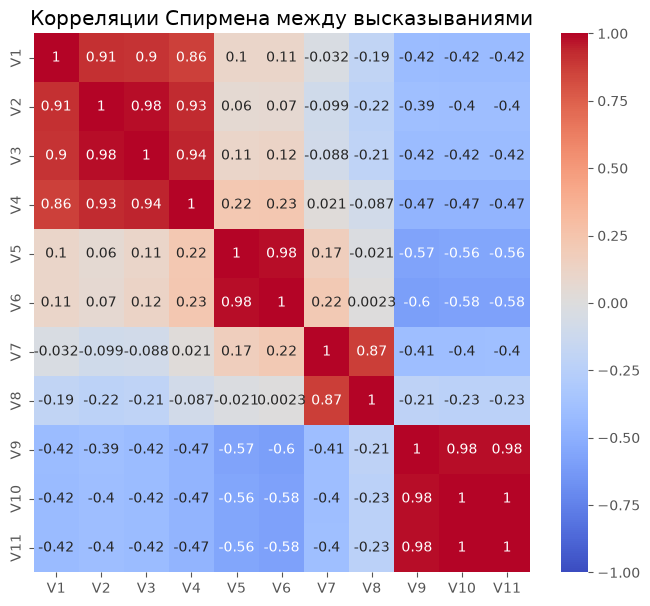

In [8]:
corr_matrix = lollipops.corr(method='spearman')

plt.figure(figsize=(8, 7))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Корреляции Спирмена между высказываниями')
plt.show()

Для порядковой шкалы используется коэффициент Спирмена: он опирается на ранги и не требует
предположения о равенстве интервалов между соседними градациями.

**Блоки признаков.** `V10/V11` связаны строго монотонно (коэффициент корреляции = 1.00); 0.98 у пар `V2/V3`,
`V9/V10`, `V9/V11`, `V5/V6`; у `V7/V8` связь слабее - 0.87. Выделяются четыре блока признаков,
что подтверждает гипотезу Н1 в части числа блоков.

**Блоки взаимоисключающие.** Корреляции между блоками отрицательные (V9 против V5/V6 даёт
-0.57, V4 против V9-V11 даёт -0.47). Респондент покупает леденцы либо от горла, либо вместо
конфет, но не одновременно. Для маркетинга это означает, что сегменты не пересекаются и
продукт для одного сегмента вряд ли подойдет другому.

**Перекос по размеру блоков.** В блоке `"свежесть"` 4 переменные, в блоке `"самочувствие"` 3,
в блоках `"сладкое"` и `"концентрация"` по 2, поэтому мотив
`"свежесть"` влияет на расстояние между респондентами вдвое сильнее, чем `"замена сладкому"`, -
не из-за важности мотива, а из-за числа заданных по нему вопросов.

### Шаг 8. Нужна ли стандартизация

Все переменные измерены в одной шкале, поэтому выравнивать единицы измерения не требуется.
При этом разброс у переменных различается: по V4 не-нейтральных ответов 164, по V7 - 100.
Стандартизация выровняла бы дисперсии и тем самым усилила вклад переменных, по которым
респонденты почти не различаются, то есть подняла бы шум.

**Решение: стандартизация не применяется.**

### Шаг 9. Выбор метрики расстояния

Манхэттенское расстояние теоретически корректнее для порядковой шкалы: оно складывает
разности ступеней линейно, тогда как евклидово возводит их в квадрат и тем самым
предполагает равенство интервалов между градациями.

Однако метод Уорда определён только для евклидовой метрики, а он входит в сравнение как
наиболее вероятный кандидат на "ясный результат". Чтобы сравнение методов было корректным,
все методы считаются в одной метрике.

**Решение: евклидово расстояние (с допущением о квазиинтервальности шкал).**

## Кластеризация

Иерархический кластерный анализ проводится функцией `linkage` из `scipy`.
Сравниваются четыре метода связи: `ward`, `average`, `complete`, `single`.

Критерии выбора метода объявляются **до** расчетов:

1. **силуэт** (`sklearn.metrics.silhouette_score`) - качество разбиения;
2. **кофенетическая корреляция** (`scipy.cluster.hierarchy.cophenet`) - насколько точно
   дендрограмма передает исходные расстояния;
3. **интерпретируемость** - читаемость дерева, сопоставимость размеров сегментов и
   возможность содержательно описать профили.

### Шаг 10. Число кластеров по высотам слияний

In [9]:
# Определяем методы и предполагаемое количество кластеров
methods = ['ward', 'average', 'complete', 'single']
K = 4

In [10]:
def last_heights(
    data: pd.DataFrame,
    method: str,
    n: int = 15,
    metric: str = 'euclidean',
) -> pd.DataFrame:
    """Таблица последних слияний: высота, разрыв до следующего уровня и его доля.

    Parameters
    ----------
    data : pd.DataFrame
        Таблица наблюдений.
    method : str
        Метод связи для linkage.
    n : int, optional
        Сколько последних слияний показать.
    metric : str, optional
        Метрика расстояния.

    Returns
    -------
    pd.DataFrame
        Индекс — число кластеров k; колонки — высота слияния, разрыв
        до следующего уровня и относительный разрыв.
    """
    Z = linkage(data, method=method, metric=metric)

    heights = Z[:, 2][-n:][::-1]
    gap = np.append(-np.diff(heights), np.nan)

    return pd.DataFrame(
        {
            'height': heights.round(2),
            'gap': gap.round(2),
            'rel_gap': (gap / heights).round(2),
        },
        index=pd.Index(np.arange(2, 2 + len(heights)), name='k'),
    )

In [11]:
heights_table = pd.concat(
    [last_heights(lollipops, m) for m in methods],
    axis=1,
    keys=methods,
)
heights_table

ward                average               complete               single  \
   height    gap rel_gap  height   gap rel_gap   height   gap rel_gap height   
k                                                                              
2   51.71   8.26    0.16    5.15  0.50    0.10     7.35  0.79    0.11   2.83   
3   43.44  13.22    0.30    4.65  0.62    0.13     6.56  0.90    0.14   2.65   
4   30.22  17.19    0.57    4.03  0.96    0.24     5.66  0.97    0.17   2.45   
5   13.03   2.81    0.22    3.07  0.32    0.10     4.69  0.95    0.20   2.00   
6   10.22   1.72    0.17    2.76  0.33    0.12     3.74  0.74    0.20   2.00   
7    8.49   1.31    0.15    2.43  0.15    0.06     3.00 -0.00   -0.00   1.73   
8    7.19   0.01    0.00    2.28  0.06    0.03     3.00  0.17    0.06   1.73   
9    7.18   0.63    0.09    2.22  0.12    0.05     2.83 -0.00   -0.00   1.73   
10   6.55   0.57    0.09    2.10  0.03    0.01     2.83  0.38    0.13   1.73   
11   5.98   0.55    0.09    2.07  0.06    0.03     2.45 -0.00   -0.00   1.73   
12   5.43   0.05    0.01    2.02  0.02    0.01     2.45 -0.00   -0.00   1.73   
13   5.38   0.00    0.00    2.00  0.08    0.04     2.45  0.21    0.09   1.73   
14   5.38   0.27    0.05    1.92  0.06    0.03     2.24 -0.00   -0.00   1.73   
15   5.12   0.09    0.02    1.86  0.06    0.03     2.24 -0.00   -0.00   1.73   
16   5.02    NaN     NaN    1.80   NaN     NaN     2.24   NaN     NaN   1.41   

                  
     gap rel_gap  
k                 
2   0.18    0.06  
3   0.20    0.07  
4   0.45    0.18  
5  -0.00   -0.00  
6   0.27    0.13  
7  -0.00   -0.00  
8  -0.00   -0.00  
9  -0.00   -0.00  
10 -0.00   -0.00  
11 -0.00   -0.00  
12 -0.00   -0.00  
13 -0.00   -0.00  
14 -0.00   -0.00  
15  0.32    0.18  
16   NaN     NaN

У `ward` наибольший разрыв `17.19` приходится на переход от `k=4` к `k=5`
и составляет больше половины высоты; у `average` и `complete` разрывы между соседними
уровнями близки друг к другу, выраженного локтя нет. 
`k = 4` уверенно указывает только `ward` - `average` и `complete` этому не противоречат, но сами четкого локтя не дают.

### Шаг 11. Дендрограммы

In [ ]:
def plot_dendrogram(
    data: pd.DataFrame,
    method: str,
    ax: plt.Axes,
    metric: str = 'euclidean',
    p: int = 30,
) -> None:
    """Рисует усечённую дендрограмму для заданного метода связи.

    Parameters
    ----------
    data : pd.DataFrame
        Таблица наблюдений.
    method : str
        Метод связи для linkage.
    ax : plt.Axes
        Область, в которой рисовать график.
    metric : str, optional
        Метрика расстояния.
    p : int, optional
        Сколько последних слияний показать (truncate_mode='lastp').
    """
    Z = linkage(data, method=method, metric=metric)

    dendrogram(Z, truncate_mode='lastp', p=p, color_threshold=-1, ax=ax)
    ax.set_title(f'Метод {method}')
    ax.set_ylabel('Высота слияния')

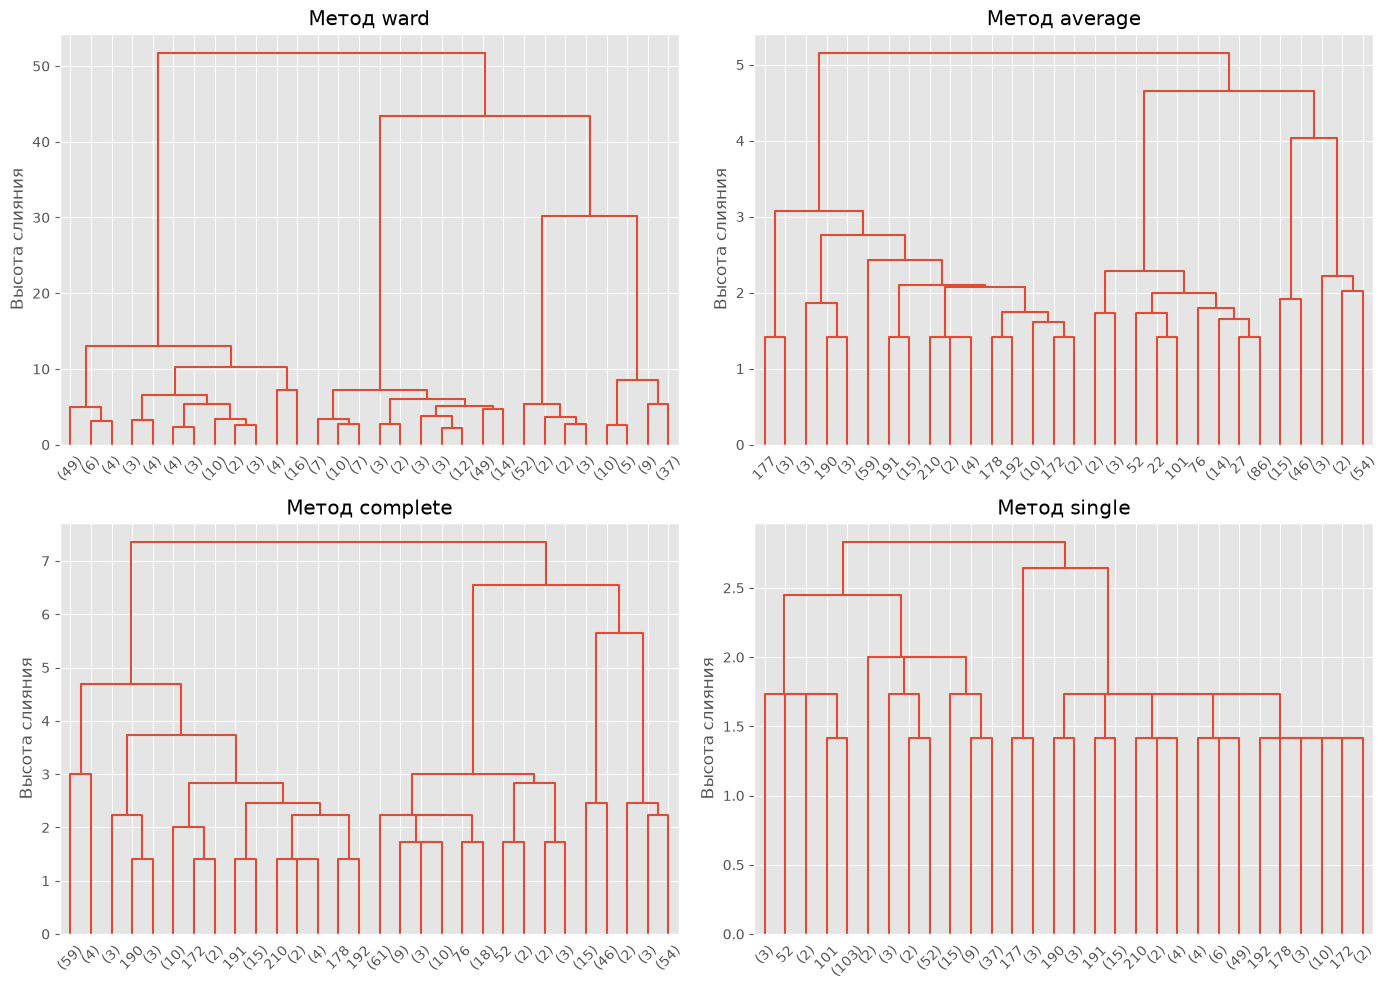

In [13]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for ax, m in zip(axes.flat, methods):
    plot_dendrogram(lollipops, m, ax=ax)

fig.tight_layout()
plt.show()

`Ward`, `average` и `complete` расщепляются на 4 сопоставимые ветви.
`Single` ведет себя иначе: уже при `k = 3` от дерева отделяется группа из 4
объектов, остальная масса остается слитой - **эффект цепочки**.

У `ward` четвертое слияние происходит на высоте `30.22`, следующее - только на `13.03`; 
между ними слияний нет, разрез проведен на высоте `21.63`, что
соответствует разрыву в таблице высот. У `average` и `complete` разрыв в том же
месте, но зрительно меньше. У `single` пустого промежутка нет, поэтому высоту
разреза определить сложно.

При `k = 4` размеры ветвей: 
- `ward` [108, 110, 59, 61], 
- `average` [108, 110, 61, 59], 
- `complete` [108, 110, 61, 59], 
- `single` [110, 120, 4, 104]. 

Требованию "достаточно большие сегменты" удовлетворяют `ward`, `average`, `complete` (и они дают одно и то же разбиение).

### Шаг 12. Сравнение методов по формальным метрикам

In [ ]:
def cluster_report(
    data: pd.DataFrame,
    method: str,
    k: int,
    metric: str = 'euclidean',
) -> dict:
    """Считает характеристики качества для одного метода связи.

    Parameters
    ----------
    data : pd.DataFrame
        Таблица наблюдений: строки - объекты, колонки - признаки.
    method : str
        Метод связи для linkage ('ward', 'average', 'complete', 'single').
    k : int
        Число кластеров, на котором сравниваются методы.
    metric : str, optional
        Метрика расстояния.
        
    Returns
    -------
    dict
        Строка сводной таблицы: метод, кофенетическая корреляция,
        силуэт и размеры кластеров.
    """
    dist = pdist(data, metric=metric)
    Z = linkage(dist, method=method)

    coph = cophenet(Z, dist)[0]
    labels = fcluster(Z, t=k, criterion='maxclust')
    silhouette = silhouette_score(data, labels, metric=metric)
    sizes = pd.Series(labels).value_counts().sort_index().tolist()

    return {
        'method': method,
        'cophenet': round(coph, 3),
        'silhouette': round(silhouette, 3),
        'sizes': sizes,
    }

In [15]:
report = pd.DataFrame([cluster_report(lollipops, m, k=K) for m in methods])
report

,method,cophenet,silhouette,sizes
0,ward,0.912,0.727,"[108, 110, 59, 61]"
1,average,0.935,0.727,"[108, 110, 61, 59]"
2,complete,0.928,0.727,"[108, 110, 61, 59]"
3,single,0.913,0.560,"[110, 120, 4, 104]"


Метод `single` выпадает из общей картины: силуэт `0.560` против `0.727` у остальных, один из
кластеров содержит 4 объекта при сотне в остальных. Метод не подходит под задачу сегментации, где требуются
сопоставимые по размеру группы.

По метрике `cophenet` у `average` показатель выше (`0.935`), но это структурное свойство метода - 
он устроен так, чтобы сохранять средние расстояния, поэтому решающим аргументом не является.

Силуэт у `ward`, `average` и `complete` совпадает, размеры кластеров - тоже.
Проверим, одно ли это разбиение.

### Шаг 13. Совпадают ли разбиения методов ward и average

In [16]:
link_ward = linkage(lollipops, method='ward', metric='euclidean')
labels_ward = fcluster(link_ward, t=K, criterion='maxclust')

link_average = linkage(lollipops, method='average', metric='euclidean')
labels_average = fcluster(link_average, t=K, criterion='maxclust')

pd.crosstab(labels_ward, labels_average)

col_0,1,2,3,4
row_0,,,,
1,108,0,0,0
2,0,110,0,0
3,0,0,0,59
4,0,0,61,0


В каждой строке и каждом столбце ровно одно ненулевое значение - **разбиения идентичны**.

### Шаг 14. Выбор метода

Метод `single` не подходит под задачу из-за эффекта цепочки: он даёт кластеры
несопоставимого размера, что противоречит требованию измеримых и достаточно больших
сегментов.

Формальные метрики не различают `ward`, `average` и `complete` - разбиение у них одно и то же.
Выбор делается по двум дополнительным основаниям:

1. `Ward` на каждом шаге объединяет пару кластеров так, чтобы прирост
   внутригрупповой дисперсии был минимальным. Он оптимизирует компактность и склонен
   давать кластеры сопоставимого размера - именно это требуется для сегментации.
2. **Четкость локтя.** Только у `ward` таблица высот дает выраженный разрыв, однозначно
   указывающий на `k = 4`.

**Решение: для дальнейшего анализа используется метод Уорда, k = 4.**

### Шаг 15. Подтверждение числа кластеров силуэтом

Число кластеров выбрано по высотам слияний. Проверим его вторым, независимым критерием -
силуэтом для выбранного метода при разном k.

In [17]:
sil_by_k = pd.DataFrame(
    [{'k': k, **cluster_report(lollipops, 'ward', k=k)} for k in range(2, 9)]
).set_index('k')

sil_by_k[['silhouette', 'sizes']]

,silhouette,sizes
k,,
2,0.455,"[108, 230]"
3,0.614,"[108, 110, 120]"
4,0.727,"[108, 110, 59, 61]"
5,0.698,"[59, 49, 110, 59, 61]"
6,0.729,"[59, 29, 20, 110, 59, 61]"
7,0.731,"[59, 29, 20, 110, 59, 15, 46]"
8,0.744,"[59, 29, 4, 16, 110, 59, 15, 46]"


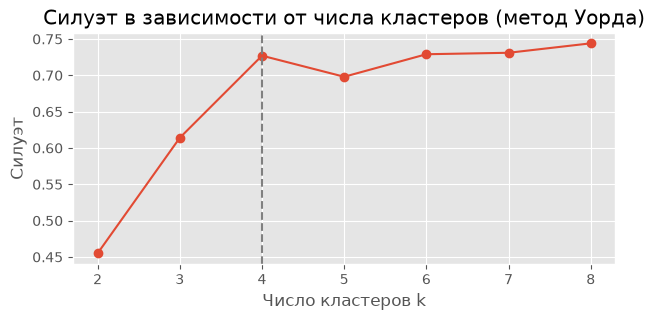

In [18]:
plt.figure(figsize=(7, 3))
plt.plot(sil_by_k.index, sil_by_k['silhouette'], marker='o')
plt.axvline(x=4, linestyle='--', color='grey')
plt.xlabel('Число кластеров k')
plt.ylabel('Силуэт')
plt.title('Силуэт в зависимости от числа кластеров (метод Уорда)')
plt.show()

Резкий прирост силуэта заканчивается при `k = 4`: `0.455` -- `0.614` -- `0.727`. При `k = 5`
показатель снижается до `0.698`, дальше кривая выходит на плато.

**Вывод: k = 4 подтверждено вторым критерием.**

### Шаг 16. Итоговая дендрограмма выбранного метода

Порог разреза: 21.62


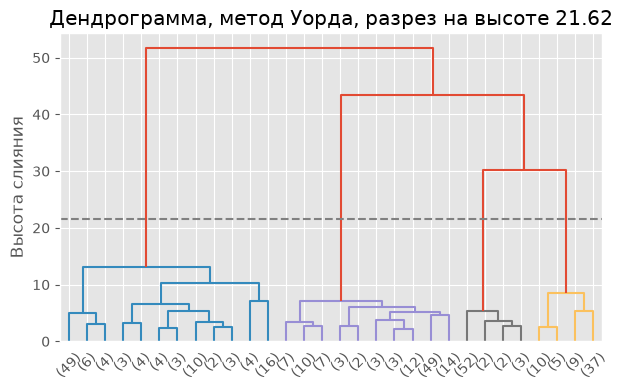

In [ ]:
def cut_threshold(Z: np.ndarray, k: int) -> float:
    """Высота разреза, дающая ровно k кластеров.

    Берется середина промежутка между k-м и (k−1)-м по величине слияниями:
    выше этой высоты остаётся k−1 слияние, то есть дерево распадается на k ветвей.
    """
    return (Z[-k, 2] + Z[-k + 1, 2]) / 2


threshold = cut_threshold(link_ward, K)
print(f'Порог разреза: {threshold:.2f}')

plt.figure(figsize=(7, 4))
dendrogram(link_ward, truncate_mode='lastp', p=30, color_threshold=threshold)
plt.axhline(y=threshold, linestyle='--', color='grey')
plt.title(f'Дендрограмма, метод Уорда, разрез на высоте {threshold:.2f}')
plt.ylabel('Высота слияния')
plt.show()

Порог попадает внутрь разрыва между высотами `13.03` и `30.22` - в области, где слияний нет.
Под порогом дерево распадается на четыре ветви.

## Профили кластеров

Создадим копию датасета и добавим колонку с метками кластеров, полученными методом `ward`.

In [20]:
lollipops_copy = lollipops.copy()
lollipops_copy['labels'] = labels_ward
lollipops_copy

,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11,labels
0,4,5,5,5,3,3,3,3,3,3,3,2
1,5,4,5,5,3,3,3,3,3,3,3,2
2,5,5,4,5,3,3,3,3,3,3,3,2
3,5,4,5,5,3,3,3,3,3,3,3,2
4,4,5,5,5,3,3,3,3,3,3,3,2
...,...,...,...,...,...,...,...,...,...,...,...,...
333,3,3,3,3,3,3,5,5,3,3,3,3
334,3,3,3,3,3,3,5,5,3,3,3,3
335,3,3,3,3,3,3,5,5,3,3,3,3
336,3,3,3,3,3,3,5,5,3,3,3,3


### Шаг 17. Размеры и доли сегментов

In [21]:
# Количество объектов в каждом классе
cluster_size = lollipops_copy['labels'].value_counts().sort_index()

# Доля сегмента от общего числа:
cluster_share = (lollipops_copy['labels'].value_counts() / len(lollipops_copy) * 100).sort_index()

display(cluster_size, cluster_share.round(2))


labels
1    108
2    110
3     59
4     61
Name: count, dtype: int64

labels
1    31.95
2    32.54
3    17.46
4    18.05
Name: count, dtype: float64

### Шаг 18. Выбор сводного показателя для профиля

**Строим профиль кластера:**

Необходимо решить, какую статистику будем брать для создания профилей. Данные у нас в порядковой шкале, значит среднее (`mean`) - это не совсем подходящий инструмент.
Медиана подходит лучше для порядковых шкал. 

Однако, если принять допущение о квазиинтервальности шкал, среднее дополнит вывод, полученный с помощью медианы.

In [22]:
means = lollipops_copy.groupby('labels').mean()
medians = lollipops_copy.groupby('labels').median()

display(means)
display(medians)

,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11
labels,,,,,,,,,,,
1,2.824074,2.833333,2.768519,2.620370,2.611111,2.583333,2.750000,2.916667,4.953704,4.814815,4.861111
2,4.845455,4.800000,4.836364,4.681818,3.036364,3.036364,3.000000,2.990909,3.072727,3.045455,3.045455
3,3.000000,2.966102,2.966102,2.915254,2.915254,2.949153,4.915254,4.915254,3.000000,3.000000,3.000000
4,3.000000,3.000000,3.000000,3.000000,4.852459,4.852459,3.000000,2.918033,2.754098,2.754098,2.754098


,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11
labels,,,,,,,,,,,
1,3.0,3.0,3.0,3.0,3.0,3.0,3.0,3.0,5.0,5.0,5.0
2,5.0,5.0,5.0,5.0,3.0,3.0,3.0,3.0,3.0,3.0,3.0
3,3.0,3.0,3.0,3.0,3.0,3.0,5.0,5.0,3.0,3.0,3.0
4,3.0,3.0,3.0,3.0,5.0,5.0,3.0,3.0,3.0,3.0,3.0


Медианы позволяют выявить сегменты: 
- `label1`: сегмент с пиком в `V9`, `V10`, `V11` - улучшение самочувствия
- `label2`: сегмент с пиком в `V1`, `V2`, `V3`, `V4` - свежесть дыхания
- `label3`: сегмент с пиком в `V7`, `V8` - концентрация внимания
- `label4`: сегмент с пиком в `V5`, `V6` - замена сладкого.
    
Среднее по кластерам дает информацию о склонности респондентов выбирать нейтральный (3) или более категоричный ответ (2) для противоположных мотивов. 

Формально наша гипотеза Н2 о том, что доминирующим сегментом окажется `"свежесть дыхания"`, подтвердилась, 
однако на практике отрыв от первого сегмента `"улучшение самочувствия"` меньше процента. 
Значит, корректнее говорить о **двух сопоставимых по размеру крупных сегментах.**

### Шаг 19. Доля согласия по сегментам

В качестве метрики для маркетологов будем использовать **долю согласия** (т.е. доля оценок 4 и 5) - она будет показывать, сколько опрошенных сегмента согласны, что мотивом покупки леденцов служит конкретная цель.

In [23]:
# Доля согласных опрошенных в сегменте

value_cols = lollipops.columns

agree = lollipops_copy[value_cols] >= 4
agree_share = agree.groupby(lollipops_copy['labels']).mean()

(agree_share * 100).round(2)

,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11
labels,,,,,,,,,,,
1,0.0,3.7,3.7,3.7,0.00,0.00,6.48,6.48,100.00,100.00,100.00
2,100.0,100.0,100.0,100.0,3.64,3.64,0.00,2.73,7.27,4.55,4.55
3,0.0,0.0,0.0,0.0,0.00,0.00,100.00,100.00,0.00,0.00,0.00
4,0.0,0.0,0.0,0.0,100.00,100.00,0.00,0.00,0.00,0.00,0.00


Выводы по таблице согласия: 

1 - внутри своего блока доля согласия близка к `100%`, а за его пределами - около 0.

2 - сегменты 3 и 4 полностью чисты: все `100%` респондентов этих сегментов согласны с высказываниями блока. 

3 - данные из таблицы подтверждают гипотезу о непересекающихся сегментах.

Соберем профили по каждому сегменту в одну таблицу:

In [24]:
# Словарь сегментов
segments = {
    1: ('Лечебный', ['V9', 'V10', 'V11']),
    2: ('Свежесть дыхания', ['V1', 'V2', 'V3', 'V4']),
    3: ('Концентрация', ['V7', 'V8']),
    4: ('Вместо конфет', ['V5', 'V6'])
}

# Характеристики сегментов
rows = []
for label, (title, block) in segments.items():
    rows.append({
        'label': label,
        'title': title,
        'size': cluster_size[label],
        'share_%': round(cluster_share[label], 1),
        'key_vars': ', '.join(block),
        'agree_block_%': round(agree_share.loc[label, block].mean() * 100, 1)
    })
    
# Собираем таблицу
summary = pd.DataFrame(rows).set_index('label')
summary

,title,size,share_%,key_vars,agree_block_%
label,,,,,
1,Лечебный,108,32.0,"V9, V10, V11",100.0
2,Свежесть дыхания,110,32.5,"V1, V2, V3, V4",100.0
3,Концентрация,59,17.5,"V7, V8",100.0
4,Вместо конфет,61,18.0,"V5, V6",100.0


Согласно итоговой таблице сегментов, выделяется **4 сегмента**: 2 крупных сегмента (`около 32%`) и два поменьше (`около 18%`).
Минимальный размер сегмента = 59 человек.

Построим тепловую карту профилей:

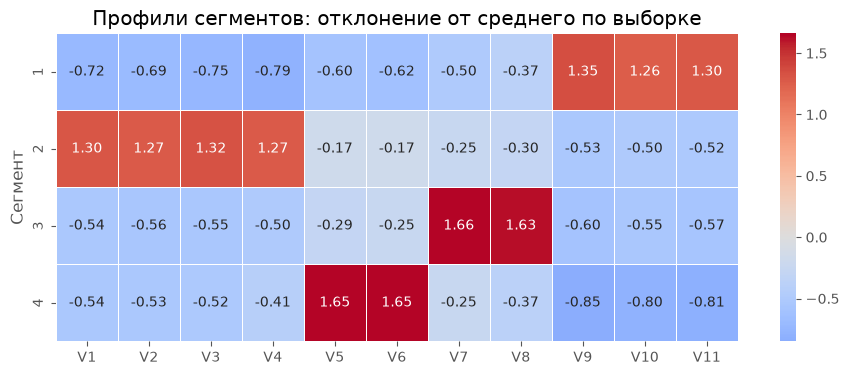

In [25]:
profile = lollipops_copy.groupby('labels')[value_cols].mean()
deviation = profile - lollipops[value_cols].mean()

plt.figure(figsize=(11, 4))
sns.heatmap(
    deviation,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    center=0,
    linewidths=0.5,
)
plt.title('Профили сегментов: отклонение от среднего по выборке')
plt.ylabel('Сегмент')
plt.show()

Выводы по тепловой карте:

- 1 сегмент (`Лечебный`) и 4 сегмент (`Вместо конфет`): респонденты склонны резко отрицать чужие мотивы;
- 2 сегмент (`Свежесть дыхания`) и 3 сегмент (`Концентрация`): респонденты относительно нейтральны к чужим мотивам;

## Выводы

### Число кластеров

В ходе работы было выявлено оптимальное число кластеров: `k = 4`, что подтверждено двумя независимыми критериями:

1) **высоты слияний** - наибольший разрыв `ward` (`17.19`) при переходе от 4 к 5, более половины высоты; у `average` и `complete` разрыв в том же месте, но выражен слабее;

2) **силуэт** - резкий прирост заканчивается на `k = 4`, при k = 5 снижение, далее плато.

### Выбранный метод

После сравнения методов `ward`, `average`, `complete`, `single` по 3 критериям, `single` отвергнут из-за эффекта цепочки (группа из 4 объектов уже при k = 3);
- `ward`, `average` и `complete` дают идентичное разбиение, что подтверждено кросс-таблицей;
- выбран `ward` - оптимизирует компактность, даёт сопоставимые по размеру кластеры, единственный с выраженным локтем.

### Сегменты

Результатом работы стало выделение 4 сегментов с названиями:
    
1) Лечебный
2) Свежесть дыхания
3) Концентрация
4) Вместо конфет

Статистика по сегментам приведена в таблице `summary`. 

Структура сегментов двухуровневая: мы выделили два крупных сегмента (ок. 32%) и два меньших сегмента (ок. 18%).

Каждый сегмент имеет пик ровно по одному блоку переменных, пересечений у сегментов нет.
Из чего можно сделать вывод, что мотивы взаимоисключающие - продукт для одного сегмента не подойдет другому.

### Проверка гипотез

1) Н1 о 4 блоках признаков - подтверждена корреляционной матрицей.
2) Гипотеза о нейтральном сегменте - опровергнута: шаблона из одних троек нет.
3) Гипотеза о доминировании сегмента свежести - формально да (110 против 108),
    но разница в два наблюдения лежит в пределах погрешности; корректнее говорить
    о двух сопоставимых ведущих сегментах.
4) Соответствие сегментов блокам - подтверждено.

### Практический смысл для заказчика

**Что следует из сегментации?**: 

1) Сегментация указала на основные мотивы потребления леденцов, выделив четыре сегмента размером 32.0%, 32.5%, 17.5%, 18.0%.
2) Сегменты не пересекаются - коммуникация и продукт должны быть разными для разных групп.
3) 2/3 рынка приходятся на два крупных сегмента: "Лечебный" и "Свежесть дыхания" - возможно рекламную кампанию стоит сосредоточить на них.
4) Нейтрального сегмента нет - у каждого респондента есть выраженный мотив.

### Ограничения

1. Перекос по числу переменных в блоках (4/3/2/2): мотив «свежесть» влияет на расстояние сильнее остальных. 
2. Допущение о квазиинтервальности порядковой шкалы, принятое ради евклидовой метрики.
3. 293 дубликата из 338 строк: нижние ветви дендрограммы сливаются на нулевой высоте, мелкая структура дерева не интерпретируется.